# Questão 2 — MLP para classificação da qualidade de vinhos

**Aprendizado Profundo (UFPB, 2026.2)**

Neste notebook resolvemos a Questão 2 da lista: uma **Rede Perceptron de Múltiplas Camadas (MLP)** que prevê a qualidade de vinhos a partir de suas características físico-químicas, usando o **Wine Quality Dataset (UCI)**.

A nota de qualidade (0 a 10) é transformada em **3 classes**:

- **baixa**: notas de 0 a 4;
- **média**: notas 5 e 6;
- **alta**: notas de 7 a 10.

Roteiro:

1. Carregar os dados e fazer a **análise exploratória** (valores ausentes, duplicados, distribuição das classes, correlações).
2. **Pré-processar** (atributos redundantes, divisão estratificada, normalização) e **avaliar a necessidade de balanceamento**.
3. Definir a **arquitetura** pela Regra de Ouro da Generalização.
4. Escolher os hiperparâmetros por **Grid Search com validação cruzada**, usando **early stopping**.
5. Treinar o modelo final e apresentar curvas de erro, **matriz de confusão** e as métricas **accuracy, precision, recall e f1-score**.

## 0. Preparação

Importamos as bibliotecas, fixamos as sementes (para o grupo todo obter os mesmos resultados) e definimos funções auxiliares:

- `metricas_clf`: calcula accuracy, precision, recall e f1-score (média **macro**, que dá o mesmo peso a cada classe).
- `treinar_clf`: laço de treinamento com **early stopping** (para quando o erro de validação deixa de melhorar) e suporte a técnicas de balanceamento.
- `plotar_curvas` e `plotar_matriz_confusao`: gráficos.

In [1]:
import copy
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 100
ROTULOS = ["baixa", "média", "alta"]


def para_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


def metricas_clf(y_real, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_real, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_real, y_pred), "precision": p, "recall": r, "f1-score": f}


def criar_mlp(n_entrada, n_ocultos, n_saidas=3):
    # Uma camada escondida (ReLU); a saída tem um neurônio por classe (logits)
    return nn.Sequential(nn.Linear(n_entrada, n_ocultos), nn.ReLU(), nn.Linear(n_ocultos, n_saidas))


def treinar_clf(modelo, X_tr, y_tr, X_val, y_val, lr, weight_decay=0.0, batch_size=128,
                balanceamento="nenhum", max_epocas=200, paciencia=15):
    # Treina com Adam e entropia cruzada. Para quando o erro de validação não melhora por
    # `paciencia` épocas (early stopping) e restaura os pesos da melhor época.
    X_a, y_a, pesos = X_tr, y_tr, None
    if balanceamento == "smote":
        X_a, y_a = SMOTE(random_state=SEED).fit_resample(X_tr, y_tr)
    elif balanceamento == "pesos":
        pesos = para_tensor(len(y_tr) / (3 * np.bincount(y_tr)))
    X_a, y_a = para_tensor(X_a), torch.tensor(y_a, dtype=torch.long)
    X_o, y_o = para_tensor(X_tr), torch.tensor(y_tr, dtype=torch.long)
    X_v, y_v = para_tensor(X_val), torch.tensor(y_val, dtype=torch.long)

    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    perda_treino = nn.CrossEntropyLoss(weight=pesos)
    perda_aval = nn.CrossEntropyLoss()  # a avaliação usa a distribuição real das classes
    hist = {"treino": [], "validacao": []}
    melhor, melhores_pesos, sem_melhora = float("inf"), None, 0

    for _ in range(max_epocas):
        modelo.train()
        for idx in torch.randperm(len(X_a)).split(batch_size):
            otimizador.zero_grad()
            perda_treino(modelo(X_a[idx]), y_a[idx]).backward()
            otimizador.step()

        modelo.eval()
        with torch.no_grad():
            hist["treino"].append(perda_aval(modelo(X_o), y_o).item())
            hist["validacao"].append(perda_aval(modelo(X_v), y_v).item())

        if hist["validacao"][-1] < melhor - 1e-4:
            melhor, melhores_pesos, sem_melhora = hist["validacao"][-1], copy.deepcopy(modelo.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break

    modelo.load_state_dict(melhores_pesos)
    return hist


def prever(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return modelo(para_tensor(X)).argmax(dim=1).numpy()


def plotar_curvas(hist, titulo):
    melhor = int(np.argmin(hist["validacao"]))
    plt.figure(figsize=(7, 4))
    plt.plot(hist["treino"], label="Treino")
    plt.plot(hist["validacao"], label="Validação")
    plt.axvline(melhor, color="grey", linestyle="--", alpha=0.7)
    plt.scatter(melhor, hist["validacao"][melhor], color="red", s=40, zorder=5,
                label=f"Menor erro de validação (época {melhor + 1})")
    plt.xlabel("Época")
    plt.ylabel("Erro (entropia cruzada)")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def plotar_matriz_confusao(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, dados, fmt, sub in [(eixos[0], cm, "d", "Contagem"), (eixos[1], cm_norm, ".2f", "Normalizada por linha (recall)")]:
        im = ax.imshow(dados, cmap="Blues")
        ax.set_xticks(range(3), ROTULOS)
        ax.set_yticks(range(3), ROTULOS)
        ax.set_xlabel("Classe predita")
        ax.set_ylabel("Classe real")
        ax.set_title(f"{titulo}: {sub}")
        for i, j in itertools.product(range(3), range(3)):
            ax.text(j, i, format(dados[i, j], fmt), ha="center", va="center",
                    color="white" if dados[i, j] > dados.max() / 2 else "black")
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

**O que foi feito:** o ambiente está pronto. Pontos importantes sobre `treinar_clf`:

- **Early stopping com paciência de 15 épocas:** o treino para quando o erro de validação não melhora por 15 épocas seguidas, e os pesos da melhor época são restaurados. Isso evita escolher o número de épocas "no olho".
- **Balanceamento dentro do treino:** a técnica (`"nenhum"`, `"pesos"` ou `"smote"`) é aplicada **só aos dados de treino**. A validação e o teste mantêm a distribuição real das classes, senão as métricas ficariam enganosas.
- **Erro de treino medido nos dados originais:** mesmo quando o treino usa SMOTE ou pesos, a curva de treino é calculada nos dados reais de treino, para ser comparável com a de validação.

---
# 1. Dados e análise exploratória

## 1.1 Carregamento

Baixamos o dataset pelo pacote `ucimlrepo` (UCI, id 186). Ele reúne vinhos **tintos e brancos** (variante portuguesa "Vinho Verde"). A coluna `color` indica o tipo; a convertemos em um atributo binário `is_red`, para a rede poder usar essa informação.

In [2]:
vinhos = fetch_ucirepo(id=186)
df = vinhos.data.original.copy()
df["is_red"] = (df.pop("color") == "red").astype(int)
print("Formato:", df.shape)
df.head()

Formato: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


**Resultado:** são **6497 vinhos**, com **11 atributos físico-químicos**, o atributo `is_red` que criamos e a nota `quality`. Os atributos são todos numéricos.

## 1.2 Valores ausentes e duplicados

Verificamos dois problemas típicos:

- **valores ausentes**, que exigiriam imputação ou remoção;
- **linhas duplicadas**: vinhos com exatamente os mesmos valores em todas as colunas. Se uma cópia cair no treino e outra no teste, o modelo "já viu" aquele exemplo e as métricas ficam otimistas (*vazamento de dados*).

In [3]:
print("Valores ausentes no total:", int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print(f"Linhas duplicadas: {n_dup} ({n_dup / len(df):.1%})")

df = df.drop_duplicates().reset_index(drop=True)
print("Formato após remover duplicados:", df.shape)

Valores ausentes no total: 0
Linhas duplicadas: 1177 (18.1%)
Formato após remover duplicados: (5320, 13)


**Resultado:** não há valores ausentes. Há **1177 linhas duplicadas** (cerca de 18% do dataset). Removemos todas, para que o mesmo exemplo não apareça em treino e teste ao mesmo tempo. Ficamos com **5320 vinhos**.

## 1.3 Distribuição da qualidade e das classes

Primeiro a nota original (de 3 a 9) e depois as 3 classes pedidas no enunciado.

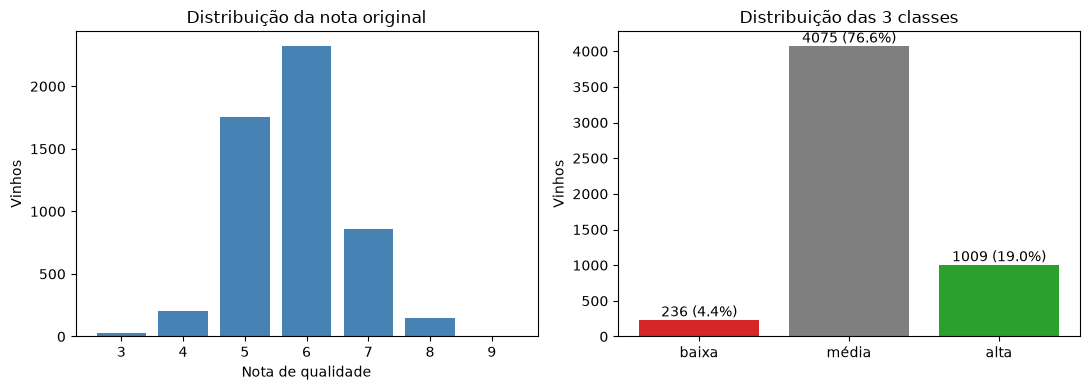

In [4]:
df["classe"] = pd.cut(df["quality"], bins=[-1, 4, 6, 10], labels=False)  # 0 = baixa, 1 = média, 2 = alta

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
contagem_nota = df["quality"].value_counts().sort_index()
eixos[0].bar(contagem_nota.index, contagem_nota.values, color="steelblue")
eixos[0].set_xlabel("Nota de qualidade")
eixos[0].set_ylabel("Vinhos")
eixos[0].set_title("Distribuição da nota original")

contagem = df["classe"].value_counts().sort_index()
barras = eixos[1].bar(ROTULOS, contagem.values, color=["tab:red", "tab:gray", "tab:green"])
for b, v in zip(barras, contagem.values):
    eixos[1].text(b.get_x() + b.get_width() / 2, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
eixos[1].set_title("Distribuição das 3 classes")
eixos[1].set_ylabel("Vinhos")
plt.tight_layout()
plt.show()

**Resultado:** a nota se concentra em 5, 6 e 7 (poucos vinhos nas pontas). Depois de agrupar, as classes ficam **muito desbalanceadas**:

| Classe | Vinhos | Proporção |
|---|---|---|
| baixa | 236 | 4,4% |
| média | 4075 | 76,6% |
| alta | 1009 | 19,0% |

A classe "média" tem **17 vezes mais** vinhos que a "baixa". Isso vai pesar na escolha da métrica e do tratamento de balanceamento (seções 2.3 e 4).

## 1.4 Distribuição e escala dos atributos

Histogramas de todos os atributos, para ver formato, escalas e valores extremos (*outliers*).

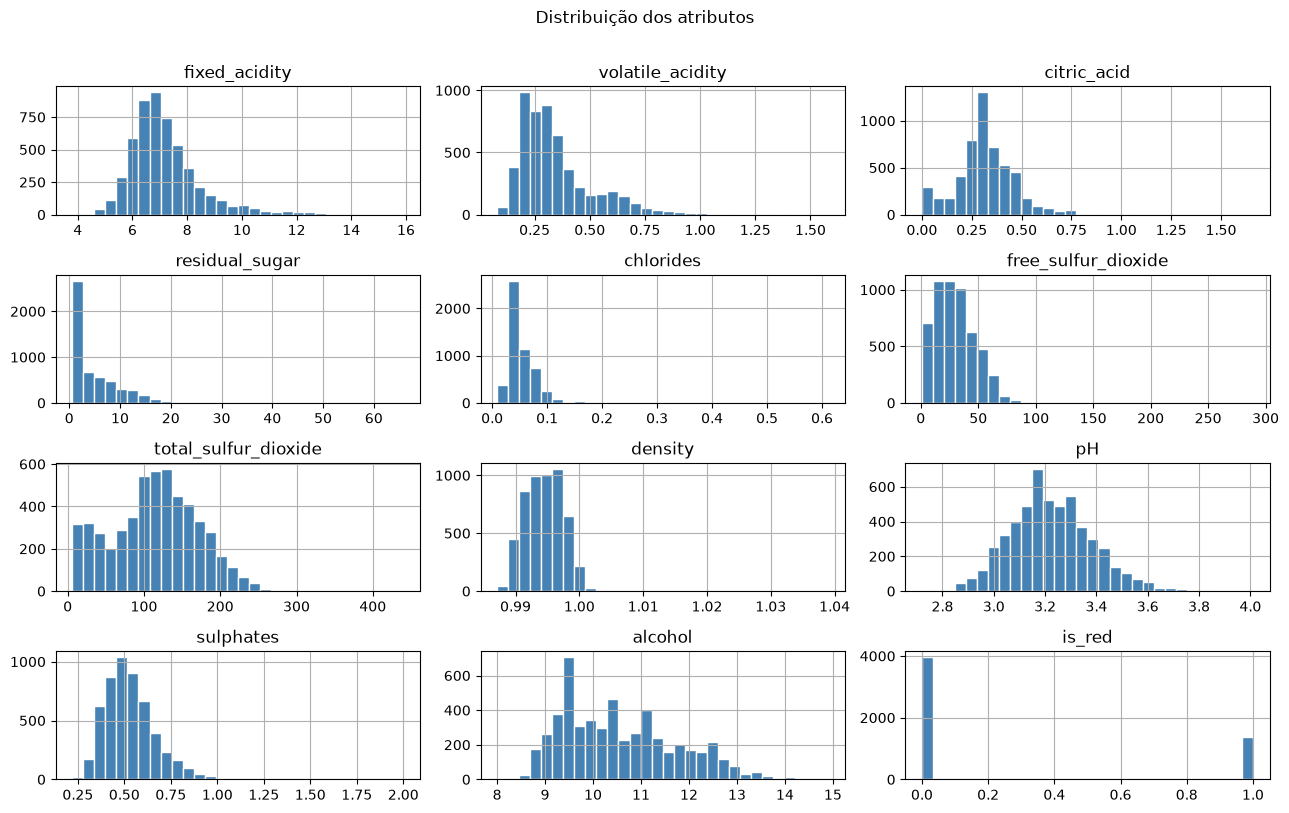

,min,max,mean,std
fixed_acidity,3.800,15.900,7.215,1.320
volatile_acidity,0.080,1.580,0.344,0.168
citric_acid,0.000,1.660,0.318,0.147
residual_sugar,0.600,65.800,5.048,4.500
chlorides,0.009,0.611,0.057,0.037
free_sulfur_dioxide,1.000,289.000,30.037,17.805
total_sulfur_dioxide,6.000,440.000,114.109,56.774
density,0.987,1.039,0.995,0.003
pH,2.720,4.010,3.225,0.160
sulphates,0.220,2.000,0.533,0.150


In [5]:
atributos = [c for c in df.columns if c not in ("quality", "classe")]
df[atributos].hist(bins=30, figsize=(13, 8), color="steelblue", edgecolor="white")
plt.suptitle("Distribuição dos atributos", y=1.01)
plt.tight_layout()
plt.show()
df[atributos].describe().T[["min", "max", "mean", "std"]].round(3)

**Análise:** os atributos têm escalas muito diferentes: `total_sulfur_dioxide` vai de 6 a 440, enquanto `density` fica entre 0,987 e 1,039. Vários atributos têm **cauda longa à direita**, com valores máximos muito acima da média: `residual_sugar` (máximo 65,8 contra média 5,0), `chlorides` (0,611 contra 0,057) e os dois dióxidos de enxofre. Esses valores extremos existem de verdade (são vinhos reais), então não os removemos, mas a diferença de escala justifica a normalização que faremos na seção 2.2.

## 1.5 Relação dos atributos com a classe

Boxplots de dois atributos por classe, para ver se eles ajudam a separar vinhos de qualidade diferente.

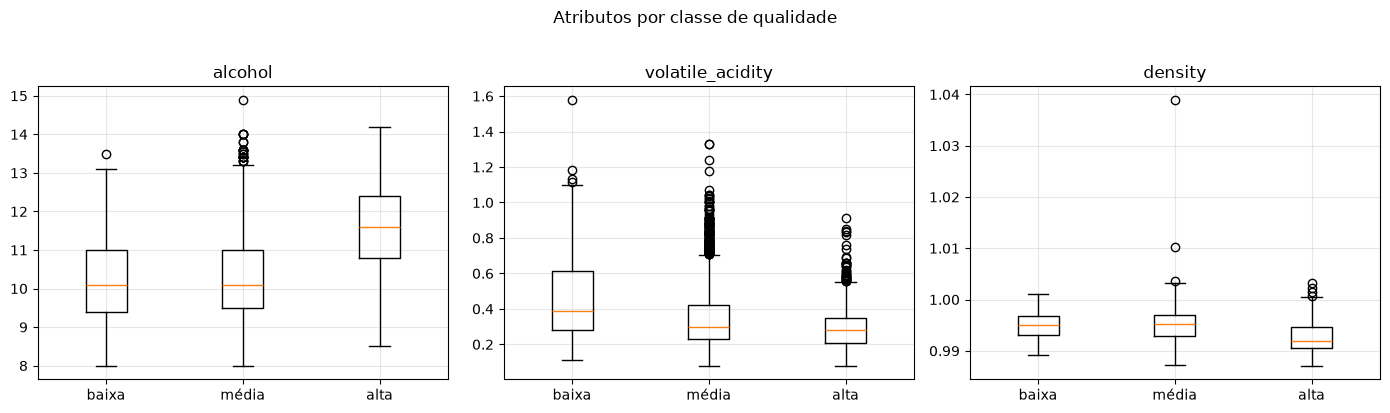

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(eixos, ["alcohol", "volatile_acidity", "density"]):
    ax.boxplot([df.loc[df["classe"] == k, col] for k in range(3)], tick_labels=ROTULOS)
    ax.set_title(col)
    ax.grid(alpha=0.3)
plt.suptitle("Atributos por classe de qualidade", y=1.02)
plt.tight_layout()
plt.show()

**Análise:** o **álcool** é o atributo que mais separa as classes: os vinhos de qualidade "alta" têm mediana de cerca de 11,6, contra cerca de 10,1 nas outras duas. A **acidez volátil** tende a ser maior nos vinhos de qualidade "baixa" (mediana perto de 0,39, contra 0,30 e 0,28) e a **densidade** é um pouco menor nos "altos". Já as classes "baixa" e "média" se sobrepõem bastante em quase todos os atributos. Isso antecipa que **separar "baixa" de "média" será difícil**, e que distinguir "alta" será mais fácil.

## 1.6 Correlações e atributos redundantes

Atributos muito correlacionados entre si carregam quase a mesma informação (são **redundantes**). Calculamos a matriz de correlação e procuramos pares com $|r| > 0{,}9$, que seriam candidatos a remoção.

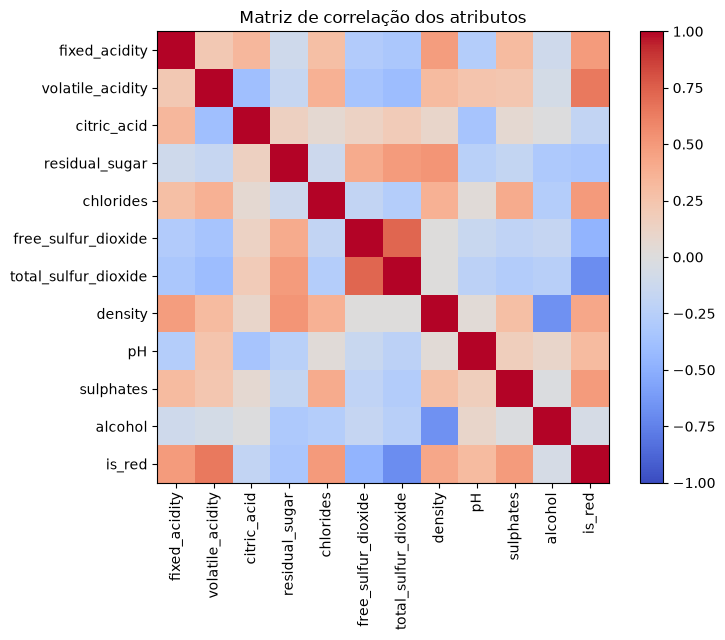

Pares mais correlacionados (|r|):
free_sulfur_dioxide   total_sulfur_dioxide    0.720
total_sulfur_dioxide  is_red                  0.694
density               alcohol                 0.668
volatile_acidity      is_red                  0.645
residual_sugar        density                 0.521
dtype: float64
Pares com |r| > 0,9: 0


In [7]:
corr = df[atributos].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
ax.set_title("Matriz de correlação dos atributos")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

pares = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Pares mais correlacionados (|r|):")
print(pares.head(5).round(3))
print("Pares com |r| > 0,9:", int((pares > 0.9).sum()))

**Análise:** **nenhum par** passa de $|r| = 0{,}9$. As maiores correlações são entre `free_sulfur_dioxide` e `total_sulfur_dioxide` (0,72), `total_sulfur_dioxide` e `is_red` (0,69) e `density` e `alcohol` (0,67). É correlação moderada, o que indica que os atributos não são redundantes a ponto de justificar remoção, e uma MLP lida bem com atributos correlacionados. Por isso **mantemos os 12 atributos**. Note que a redundância relevante deste dataset era outra: as linhas duplicadas, que já removemos na seção 1.2. A correlação de `is_red` com os dióxidos de enxofre e a acidez volátil mostra que vinho tinto e branco têm perfis químicos diferentes, o que justifica manter esse atributo.

---
# 2. Pré-processamento e balanceamento

## 2.1 Divisão em treino, validação e teste

Dividimos os dados em **70% treino, 15% validação e 15% teste**, de forma **estratificada**: cada conjunto mantém a mesma proporção de classes. Isso é essencial aqui, porque a classe "baixa" é rara e uma divisão aleatória simples poderia deixar poucos exemplos dela em algum conjunto.

- **treino**: ajusta os pesos;
- **validação**: acompanha o treinamento (early stopping);
- **teste**: usado **só no final**, para medir o desempenho real.

In [8]:
X = df[atributos].values.astype(float)
y = df["classe"].values

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

resumo = pd.DataFrame({nome: np.bincount(yy, minlength=3) for nome, yy in
                       [("Treino", y_tr), ("Validação", y_va), ("Teste", y_te)]}, index=ROTULOS)
display(resumo)
print(f"Treino: {len(X_tr)} | Validação: {len(X_va)} | Teste: {len(X_te)}")

,Treino,Validação,Teste
baixa,165,35,36
média,2853,611,611
alta,706,152,151


Treino: 3724 | Validação: 798 | Teste: 798


**Resultado:** a divisão estratificada manteve a proporção das classes nos três conjuntos (cerca de 4,4% / 76,6% / 19,0%). Note que a classe "baixa" tem só **36 vinhos no teste** e 35 na validação: qualquer métrica dessa classe será bastante instável.

## 2.2 Normalização

Os atributos têm escalas muito diferentes (por exemplo, `total_sulfur_dioxide` vai até 440 e `density` fica perto de 1). Aplicamos `StandardScaler` (média 0, desvio 1), **ajustado apenas com o treino** para não vazar informação da validação e do teste.

Mantivemos os *outliers* e não aplicamos transformação logarítmica: são vinhos reais e a padronização já deixa as escalas comparáveis. É uma simplificação.

In [9]:
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_va_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)
print("Média dos atributos no treino (≈ 0):", X_tr_s.mean(axis=0).round(2))
print("Desvio dos atributos no treino (≈ 1):", X_tr_s.std(axis=0).round(2))

Média dos atributos no treino (≈ 0): [ 0.  0.  0. -0. -0. -0. -0.  0. -0. -0. -0. -0.]
Desvio dos atributos no treino (≈ 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Resultado:** os atributos do treino ficam com média 0 e desvio 1. Validação e teste foram transformados com a média e o desvio do treino.

## 2.3 Avaliação da necessidade de balanceamento

O enunciado pede para **avaliar a necessidade** de técnicas de balanceamento. O problema é que as classes são muito desiguais (a classe "média" é a imensa maioria). Isso causa dois riscos:

1. A **acurácia engana**: um "modelo" que responde sempre "média" já acerta cerca de 77% e não aprende nada sobre vinhos bons ou ruins.
2. A rede tende a **ignorar a classe rara** ("baixa"), pois errar nela custa pouco no erro total.

Para ter uma referência, medimos esse modelo que responde sempre "média" na validação:

In [10]:
base = np.full_like(y_va, 1)  # sempre "média"
print("Baseline 'sempre média' na validação:")
print({k: round(v, 3) for k, v in metricas_clf(y_va, base).items()})

Baseline 'sempre média' na validação:
{'accuracy': 0.766, 'precision': 0.255, 'recall': 0.333, 'f1-score': 0.289}


**Resultado:** o modelo que responde sempre "média" tem **acurácia de 0,766**, mas f1-score macro de apenas **0,289** (recall 0,333, ou seja, ele só acerta uma das três classes). Isso mostra que a acurácia sozinha não serve aqui: o número a bater, para as métricas macro, é 0,29, e uma acurácia alta pode vir de uma rede que ignora as classes raras.

Comparamos **3 opções** de tratamento do desbalanceamento, todas aplicadas só ao treino:

- **`nenhum`**: sem tratamento (referência);
- **`pesos`**: a função de erro dá peso maior às classes raras (peso = $N / (3 \cdot N_{classe})$), de modo que errar numa classe rara custa mais;
- **`smote`**: cria exemplos **sintéticos** da classe rara, interpolando entre vizinhos, até igualar as classes (SMOTE, da biblioteca imbalanced-learn).

Em vez de decidir por intuição, a técnica entra como **um dos hiperparâmetros do Grid Search** (seção 4) e é escolhida pelo desempenho em validação cruzada. Como métrica de escolha usamos o **f1-score macro** (média do f1 de cada classe), e não a acurácia, justamente porque ela é enganosa com classes desbalanceadas.

---
# 3. Arquitetura da rede (Regra de Ouro da Generalização)

Em vez de escolher o número de neurônios por tentativa e erro, usamos um critério matemático baseado na Teoria da Generalização.

### Dimensão VC e número de pesos

A Teoria Estatística do Aprendizado de Vapnik-Chervonenkis (VC) demonstra que a capacidade de aprendizado de um modelo é proporcional à sua Dimensão VC ($d_{vc}$). Em Redes Neurais, a $d_{vc}$ pode ser aproximada pelo número total de pesos e viéses da rede, ou seja, $d_{vc} \approx |W|$.

### Regra de Ouro da Generalização

Para evitar *overfitting* (memorização dos dados de treino em vez de aprendizado do padrão real), a **Regra de Ouro da Generalização** estabelece que precisamos ter no mínimo 10 exemplos de treinamento independentes para cada parâmetro ajustável (peso) da rede:

$$N \ge 10 \cdot d_{vc} \implies N \ge 10 \cdot |W|$$

### Escolha de uma camada escondida

Optamos por uma rede com **uma única camada escondida**, fundamentados no **Teorema da Aproximação Universal** (Cybenko, 1989; Hornik, 1991): uma rede *feedforward* com uma única camada escondida contendo um número finito de neurônios já é suficiente para aproximar qualquer função contínua em um subconjunto compacto de $\mathbb{R}^n$. Adicionar mais camadas aumenta a dimensão VC sem necessidade teórica, dificultando a generalização. Portanto, usaremos a arquitetura mais simples:

- Entrada com $d$ neurônios (*features*)
- 1 camada escondida com $n$ neurônios
- Saída com $k$ neurônios, um por classe (aqui $k = 3$, pois o problema é de **classificação em 3 classes**; a saída passa por uma softmax dentro da função de erro)

### Cálculo do número máximo de neurônios ($n_{max}$)

Para a arquitetura de uma camada escondida com $d$ entradas e $k$ saídas, o número total de pesos $|W|$ é dado por:

- Pesos da camada escondida: $(d \cdot n)$ pesos + $n$ viéses
- Pesos da camada de saída: $(n \cdot k)$ pesos + $k$ viéses

$$|W| = (d + 1) \cdot n + (n + 1) \cdot k$$

Substituindo na Regra de Ouro $N \ge 10 \cdot |W|$ e isolando $n$:

$$N \ge 10 \cdot [(d + 1)n + (n + 1)k]$$

$$N \ge 10(d + 1)n + 10kn + 10k$$

$$N - 10k \ge 10n(d + 1 + k)$$

$$\boxed{n \le \frac{N - 10k}{10(d + k + 1)}}$$

Com $k = 1$ saída (regressão), essa fórmula se reduz a $n \le \frac{N - 10}{10(d + 2)}$, a versão com uma única saída.

**Observação:** a Regra de Ouro é uma regra prática, derivada da teoria, e não um teorema exato. Ela é conservadora e fornece um **limite superior** para $n$, não o valor ideal.

In [11]:
def n_pesos(d, n, k):
    # |W| = (d + 1) * n + (n + 1) * k: pesos e viéses da escondida e da saída
    return (d + 1) * n + (n + 1) * k


def n_neuronios_max(N, d, k):
    # n <= (N - 10k) / (10 * (d + k + 1)), arredondado para baixo (margem de segurança)
    return int((N - 10 * k) // (10 * (d + k + 1)))

**O que foi feito:** definimos `n_pesos` e `n_neuronios_max`, que implementam as duas fórmulas acima (já com $k$ saídas).

### Substituição com os valores reais

Para o nosso problema, extraímos:

- $N = 3724$ amostras de treino
- $d = 12$ atributos (11 físico-químicos e `is_red`)
- $k = 3$ classes

$$n \le \frac{3724 - 10 \cdot 3}{10(12 + 3 + 1)} = \frac{3694}{160} \approx 23{,}09$$

Arredondando para baixo, para manter a margem de segurança: **$n = 23$ neurônios na camada escondida**. O código abaixo confirma as contas.

In [12]:
N, d, k = len(X_tr), X_tr.shape[1], 3
n_h = n_neuronios_max(N, d, k)
W = n_pesos(d, n_h, k)

print(f"N = {N} amostras de treino | d = {d} atributos | k = {k} classes")
print(f"n <= ({N} - 10*{k}) / (10 * ({d} + {k} + 1)) = {(N - 10 * k) / (10 * (d + k + 1)):.2f}  ->  n = {n_h}")
print(f"|W| = ({d} + 1) * {n_h} + ({n_h} + 1) * {k} = {W} pesos")
print(f"Regra de Ouro: N = {N} >= 10 * {W} = {10 * W}  ->  {'OK' if N >= 10 * W else 'VIOLADA'}")

N = 3724 amostras de treino | d = 12 atributos | k = 3 classes
n <= (3724 - 10*3) / (10 * (12 + 3 + 1)) = 23.09  ->  n = 23
|W| = (12 + 1) * 23 + (23 + 1) * 3 = 371 pesos
Regra de Ouro: N = 3724 >= 10 * 371 = 3710  ->  OK


**Resultado:** a regra permite até 23 neurônios, o que dá 371 pesos, e $3724 \ge 3710$: a regra é satisfeita, de forma bem justa (como esperado de um arredondamento para baixo).

### Arquitetura final

| Camada | Neurônios | Ativação | Parâmetros |
|---|---|---|---|
| Entrada | 12 | | 0 |
| Escondida | 23 | ReLU | $(12 \cdot 23) + 23 = 299$ |
| Saída | 3 | Softmax (na função de erro) | $(23 \cdot 3) + 3 = 72$ |
| **Total** | | | **371** |

Usamos **ReLU** na camada escondida (padrão em dados tabulares). A saída tem 3 neurônios, um por classe, e a função de erro (entropia cruzada) aplica a softmax internamente.

In [13]:
print(criar_mlp(d, n_h))
print("Parâmetros treináveis:", sum(p.numel() for p in criar_mlp(d, n_h).parameters()))

Sequential(
  (0): Linear(in_features=12, out_features=23, bias=True)
  (1): ReLU()
  (2): Linear(in_features=23, out_features=3, bias=True)
)
Parâmetros treináveis: 371


**Resultado:** a rede construída tem 371 parâmetros, igual ao previsto pela fórmula $|W| = (d+1)n + (n+1)k$.

---
# 4. Escolha dos hiperparâmetros (Grid Search com validação cruzada)

A Regra de Ouro define o **tamanho** da rede, mas não os hiperparâmetros de treinamento. Escolhemos eles com **Grid Search**: testamos todas as combinações de uma grade e ficamos com a de melhor desempenho em **validação cruzada** (*k-fold*), que é mais confiável que um único conjunto de validação.

A grade tem 4 hiperparâmetros:

- **taxa de aprendizado** do Adam: 0,001 e 0,01;
- **regularização L2** (`weight_decay`): 0 e 0,001;
- **tamanho do lote** (*batch size*): 64 e 256;
- **balanceamento**: `nenhum`, `pesos` e `smote` (a decisão da seção 2.3).

São $2 \times 2 \times 2 \times 3 = 24$ combinações. Procedimento (**o conjunto de teste não é usado aqui**):

1. Juntamos treino e validação (4522 vinhos).
2. Dividimos em **5 partes (*folds*) estratificadas**. Para cada combinação, treinamos 5 redes: cada uma usa 4 partes para treinar e 1 para validar, com **early stopping**.
3. Escolhemos a combinação com maior **f1-score macro** médio nas partes de validação.

Em cada rede, a normalização é ajustada só com os dados de treino daquele *fold*, e o balanceamento é aplicado só ao treino do *fold*.

**Limitação:** a parte de validação de cada *fold* é usada tanto para o early stopping quanto para medir o f1. Isso deixa as notas um pouco otimistas, mas de forma igual para todas as combinações, então a comparação entre elas continua justa.

In [14]:
X_cv = np.vstack([X_tr, X_va])
y_cv = np.concatenate([y_tr, y_va])
grade = itertools.product([1e-3, 1e-2], [0.0, 1e-3], [64, 256], ["nenhum", "pesos", "smote"])

linhas = []
with torch.random.fork_rng():  # não altera os números sorteados no resto do notebook
    for lr, wd, bs, bal in grade:
        f1s, accs = [], []
        for i_tr, i_va in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_cv, y_cv):
            sc_ = StandardScaler().fit(X_cv[i_tr])
            Xa, Xv = sc_.transform(X_cv[i_tr]), sc_.transform(X_cv[i_va])
            torch.manual_seed(SEED)
            m = criar_mlp(d, n_h)
            treinar_clf(m, Xa, y_cv[i_tr], Xv, y_cv[i_va], lr=lr, weight_decay=wd, batch_size=bs, balanceamento=bal)
            met = metricas_clf(y_cv[i_va], prever(m, Xv))
            f1s.append(met["f1-score"])
            accs.append(met["accuracy"])
        linhas.append({"Taxa": lr, "L2": wd, "Lote": bs, "Balanceamento": bal,
                       "F1 macro": round(np.mean(f1s), 3), "Desvio F1": round(np.std(f1s), 3),
                       "Acurácia": round(np.mean(accs), 3)})

tabela_gs = pd.DataFrame(linhas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
melhor = tabela_gs.iloc[0]
melhor_lr, melhor_wd, melhor_bs, melhor_bal = melhor["Taxa"], melhor["L2"], int(melhor["Lote"]), melhor["Balanceamento"]
print(f"Melhor combinação: taxa={melhor_lr} | L2={melhor_wd} | lote={melhor_bs} | balanceamento={melhor_bal}")
tabela_gs.head(10)

Melhor combinação: taxa=0.01 | L2=0.001 | lote=64 | balanceamento=pesos


,Taxa,L2,Lote,Balanceamento,F1 macro,Desvio F1,Acurácia
0,0.010,0.001,64,pesos,0.542,0.020,0.665
1,0.010,0.000,64,pesos,0.538,0.021,0.670
2,0.010,0.000,64,smote,0.537,0.020,0.673
3,0.010,0.001,256,pesos,0.531,0.018,0.652
4,0.010,0.000,256,pesos,0.531,0.016,0.654
5,0.010,0.001,256,smote,0.528,0.016,0.660
6,0.010,0.001,64,smote,0.527,0.019,0.667
7,0.010,0.000,256,smote,0.526,0.014,0.662
8,0.001,0.001,64,smote,0.520,0.013,0.640
9,0.001,0.001,256,smote,0.520,0.016,0.635


**Resultado:** a melhor combinação foi **taxa 0,01, L2 de 0,001, lote de 64 e balanceamento por pesos**, com f1 macro médio de 0,542 nas validações. Pontos para ler a tabela com cuidado:

- Entre as 10 melhores combinações, as notas vão de 0,520 a 0,542, e o desvio entre folds é de cerca de 0,02. A diferença entre elas é **do tamanho do ruído**, então a escolha da melhor é pouco conclusiva.
- As 8 primeiras usam **taxa 0,01**, a maior da grade (está na borda: não testamos taxas maiores), e as 10 primeiras usam `pesos` ou `smote`.
- Entre `pesos` e `smote`, os resultados são praticamente empatados (0,542 contra 0,537).

Para avaliar o **balanceamento** isoladamente (a pergunta da seção 2.3), vemos o melhor resultado de cada técnica:

In [15]:
tabela_gs.groupby("Balanceamento")[["F1 macro", "Acurácia"]].agg(["max", "mean"]).round(3)

F1 macro        Acurácia       
                   max   mean      max   mean
Balanceamento                                
nenhum           0.509  0.496    0.794  0.792
pesos            0.542  0.522    0.670  0.640
smote            0.537  0.524    0.673  0.651

**Resposta à pergunta da seção 2.3:** **sim, o balanceamento é necessário** se o objetivo é reconhecer também as classes raras.

- Sem balanceamento, o melhor f1 macro é **0,509** e a acurácia chega a **0,79**. Com `pesos` ou `smote`, o f1 macro melhor sobe para **0,54**, mas a acurácia **cai para cerca de 0,67**.
- Ou seja, balancear **troca acurácia por f1**: a rede passa a acertar mais vinhos "baixa" e "alta", ao custo de errar mais vinhos "média" (a maioria).
- O ganho em f1 (cerca de 0,03) é modesto e do tamanho do desvio entre folds, mas é **consistente**: a média de todas as combinações com balanceamento (0,52) também fica acima da média sem balanceamento (0,50).

Escolhemos `pesos` porque empata com `smote` e é mais simples: não cria dados sintéticos e não aumenta o tempo de treino.

---
# 5. Treinamento final

Treinamos a rede com a **melhor combinação** do Grid Search, usando o conjunto de **treino** para ajustar os pesos e o de **validação** para o early stopping. O teste continua intocado.

In [16]:
torch.manual_seed(SEED)
modelo = criar_mlp(d, n_h)
hist = treinar_clf(modelo, X_tr_s, y_tr, X_va_s, y_va, lr=melhor_lr, weight_decay=melhor_wd,
                   batch_size=melhor_bs, balanceamento=melhor_bal)
print(f"Épocas treinadas: {len(hist['treino'])} | melhor época: {int(np.argmin(hist['validacao'])) + 1}")
print(f"Erro na melhor época -> treino: {hist['treino'][int(np.argmin(hist['validacao']))]:.4f} | validação: {min(hist['validacao']):.4f}")

Épocas treinadas: 27 | melhor época: 12
Erro na melhor época -> treino: 0.7057 | validação: 0.7057


**Resultado:** o treino parou na **época 27**, por *early stopping* (15 épocas sem melhora após a melhor, a época 12), e os pesos da época 12 foram restaurados. Nessa época, os erros de treino e de validação são praticamente iguais (≈ 0,706).

## 5.1 Curvas de erro de treinamento e de validação

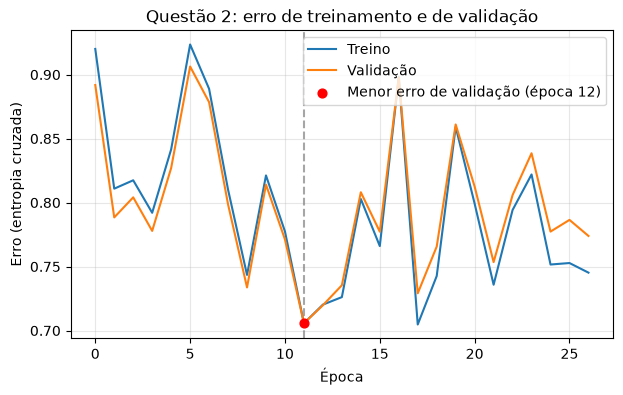

In [17]:
plotar_curvas(hist, "Questão 2: erro de treinamento e de validação")

**Análise:** as curvas de treino e de validação andam **juntas e coladas**, sem afastamento entre elas, então **não há overfitting** (coerente com a rede pequena de 371 pesos para 3724 amostras). Por outro lado, as duas **oscilam bastante** de uma época para outra e não mostram uma queda clara. Isso vem de três fatores: a taxa alta (0,01), os mini-lotes de 64 e os pesos de classe, que fazem a fronteira de decisão da classe rara se deslocar a cada época (o erro plotado é o da distribuição real, sem pesos). Por isso a "melhor época" (12) é em parte sorte, e o *early stopping* mostrou sua utilidade: parou quando as oscilações não trouxeram mais melhora.

---
# 6. Avaliação no conjunto de teste

Agora, e só agora, usamos o conjunto de **teste** (798 vinhos que a rede nunca viu, nem para treinar nem para escolher hiperparâmetros).

## 6.1 Matriz de confusão

Cada linha é a classe **real** e cada coluna a classe **predita**. A diagonal são os acertos. À direita, a mesma matriz normalizada por linha: ela mostra, para cada classe real, a fração que a rede acertou (o **recall** daquela classe).

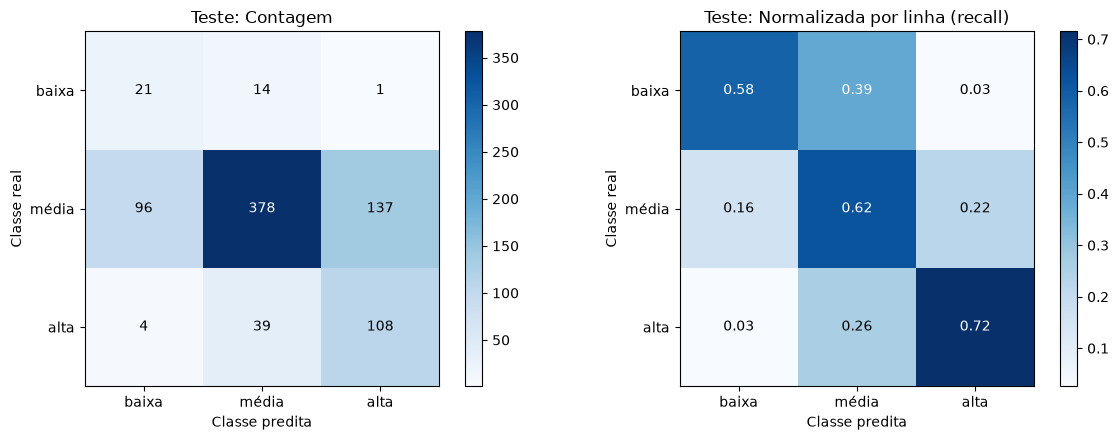

In [18]:
pred_te = prever(modelo, X_te_s)
plotar_matriz_confusao(y_te, pred_te, "Teste")

**Análise:** o **recall** por classe é de 0,58 para "baixa", 0,62 para "média" e 0,72 para "alta". Os erros se concentram em dois pontos:

- **Vinhos "média" classificados como "alta" (137) ou "baixa" (96).** São 233 dos 611 vinhos médios. É o efeito esperado dos pesos de classe: a rede foi incentivada a não ignorar as classes raras e acaba exagerando.
- **A classe "baixa" gera muitos falsos alarmes:** a rede apontou 121 vinhos como "baixa", e só 21 realmente eram (precision de 0,17). Mas ela encontrou 21 dos 36 vinhos "baixa" reais.

Os erros quase sempre são entre **classes vizinhas** ("baixa" ↔ "média" e "média" ↔ "alta"). Confundir "baixa" com "alta" é raro (1 e 4 casos), o que faz sentido: a qualidade tem uma ordem natural e as classes vizinhas se sobrepõem.

## 6.2 Métricas: accuracy, precision, recall e f1-score

- **accuracy**: fração de vinhos classificados corretamente;
- **precision** (de uma classe): dos vinhos que a rede disse ser dessa classe, quantos realmente eram;
- **recall** (de uma classe): dos vinhos que realmente eram dessa classe, quantos a rede encontrou;
- **f1-score**: média harmônica entre precision e recall.

A média **macro** dá o mesmo peso às 3 classes (penaliza ignorar a rara), e a **ponderada** pesa cada classe pelo seu tamanho.

In [19]:
relatorio = classification_report(y_te, pred_te, target_names=ROTULOS, output_dict=True, zero_division=0)
tabela_te = pd.DataFrame(relatorio).T.rename(columns={"support": "vinhos"})
tabela_te["vinhos"] = tabela_te["vinhos"].astype(int)
display(tabela_te.round(3))

comparacao = pd.DataFrame({"Rede (teste)": metricas_clf(y_te, pred_te),
                           "Baseline 'sempre média' (teste)": metricas_clf(y_te, np.full_like(y_te, 1))}).T
comparacao.round(3)

,precision,recall,f1-score,vinhos
baixa,0.174,0.583,0.268,36
média,0.877,0.619,0.726,611
alta,0.439,0.715,0.544,151
accuracy,0.635,0.635,0.635,0
macro avg,0.497,0.639,0.512,798
weighted avg,0.762,0.635,0.671,798


,accuracy,precision,recall,f1-score
Rede (teste),0.635,0.497,0.639,0.512
Baseline 'sempre média' (teste),0.766,0.255,0.333,0.289


**Análise:**

- **Acurácia: 0,635.** É menor que a do baseline "sempre média" (0,766), mas isso era esperado e não significa que a rede é pior: o baseline não reconhece nenhum vinho "baixa" ou "alta".
- **Média macro:** precision 0,497, **recall 0,639**, **f1-score 0,512**, contra 0,255, 0,333 e 0,289 do baseline. A rede supera bem o baseline em todas as métricas macro.
- **Por classe:** "média" tem o melhor f1 (0,726); "alta" tem f1 de 0,544; **"baixa" tem o pior (0,268)**, pois a precision é baixa (0,17). É a classe mais difícil: poucos exemplos (165 no treino) e muita sobreposição com "média".
- O f1 macro no teste (0,512) é um pouco menor que o da validação cruzada (0,542). É razoável: as notas da validação cruzada são levemente otimistas (seção 4), e o teste tem só 36 vinhos "baixa", então o resultado dessa classe é instável (acertar um vinho a mais muda o recall em 3 pontos percentuais).

---
# Conclusões

- **Pré-processamento:** removemos **1177 linhas duplicadas** (evitando vazamento entre treino e teste), não encontramos valores ausentes nem atributos redundantes ($|r| < 0{,}9$) e normalizamos com `StandardScaler` ajustado só no treino. A divisão em treino, validação e teste foi **estratificada**.
- **Desbalanceamento:** as classes são 4,4% / 76,6% / 19,0%, e a acurácia engana (o baseline "sempre média" tem 0,77). Usamos o **f1-score macro** para escolher modelos. O balanceamento se mostrou **necessário** para reconhecer as classes raras: ele sobe o f1 macro de cerca de 0,51 para 0,54 na validação cruzada, ao custo de cerca de 12 pontos de acurácia.
- **Arquitetura:** pela Regra de Ouro adaptada a $k = 3$ saídas, a rede tem **1 camada escondida de 23 neurônios** (371 pesos).
- **Hiperparâmetros:** Grid Search com validação cruzada de 5 folds (24 combinações) e *early stopping*. Venceu `pesos` com taxa 0,01, L2 de 0,001 e lote de 64, embora várias combinações empatem dentro do ruído.
- **Resultado no teste:** acurácia **0,635**, e f1-score macro **0,512** (precision 0,497 e recall 0,639), contra 0,289 do baseline. A rede reconhece 58% dos vinhos "baixa", 62% dos "média" e 72% dos "alta".
- **Limitações:** a classe "baixa" é difícil (f1 de 0,27) por ser rara e se sobrepor à "média", e o teste tem só 36 exemplos dela. As curvas de treino são ruidosas (taxa alta com mini-lotes e pesos de classe), e a rede foi limitada a 23 neurônios pela Regra de Ouro.